# 함정 1. 클립 값은 MSE 곡선의 바닥이다

단위 분산 Gaussian 입력을 4-bit narrow range(−7..7)로 양자화한다. 첫 실험에서는 입력 샘플을 고정하고 클립 값만 바꾼다. 수치 적분과 GPU 몬테카를로 MSE를 비교한다. 두 번째 실험에서는 샘플 수만 늘리며 min/max 클립이 커지는 모습을 확인한다.

시드는 0 하나이며, 위쪽 환경 표의 실행 시간은 마지막 셀 실행 후 갱신된다. 설계와 기대값: [학습 가이드](../docs/README.md#함정-1-클립-값은-mse-곡선의-바닥이다).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m1"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE, "integration_device": "cpu",
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'integration_device': 'cpu',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.922}

In [2]:
from quant_pitfalls.analysis import expected_mse, optimal_clip
from quant_pitfalls.quant.uniform import UniformSpec, fake_quant

spec = UniformSpec(4)
make_quantizer = lambda alpha: (lambda x: fake_quant(x, alpha, spec))
alpha_star, mse_star = optimal_clip(make_quantizer, "gaussian", 1.5, 4.0)
all_samples = torch.randn(10_000_000, generator=generator, device=DEVICE, dtype=torch.float64)
samples = all_samples[:1_000_000]
alphas = np.linspace(0.5, 5.0, 91)
integral_curve = [expected_mse(make_quantizer(float(a)), "gaussian") for a in alphas]
mc_curve = [float((make_quantizer(float(a))(samples) - samples).square().mean()) for a in alphas]
alpha_minmax = float(samples.abs().max())
selected = []
for label, alpha in [("MSE optimal", alpha_star), ("Fixed 4 sigma", 4.0), ("Min/max (1e6)", alpha_minmax)]:
    squared_error = (make_quantizer(alpha)(samples) - samples).square()
    mse = expected_mse(make_quantizer(alpha), "gaussian")
    selected.append({"method": label, "alpha": alpha, "mse_integral": mse,
                     "mse_mc": float(squared_error.mean()), "mc_standard_error": float(squared_error.std()) / len(samples)**0.5,
                     "relative_to_optimal": mse / mse_star})
print("Method | alpha | integral MSE | Monte Carlo MSE | ratio")
for row in selected:
    print(f"{row['method']:16s} | {row['alpha']:.5f} | {row['mse_integral']:.7f} | {row['mse_mc']:.7f} | {row['relative_to_optimal']:.3f}")


Method | alpha | integral MSE | Monte Carlo MSE | ratio
MSE optimal      | 2.47445 | 0.0128893 | 0.0129000 | 1.000
Fixed 4 sigma    | 4.00000 | 0.0272157 | 0.0272261 | 2.111
Min/max (1e6)    | 4.60542 | 0.0360715 | 0.0360545 | 2.799


## 샘플 수에 따른 min/max 클립

같은 시드의 중첩 샘플을 사용한다. min/max 클립이 표현할 범위를 넓히면 양자화 스텝도 커진다. 적분 MSE는 모집단에서의 오차이며, 샘플 MSE는 해당 샘플에서 직접 잰 오차다.


Samples | min/max alpha | population MSE | sample MSE
    1000 | 3.54914 | 0.0214604 | 0.0215811
   10000 | 4.20388 | 0.0300571 | 0.0301612
  100000 | 4.60542 | 0.0360715 | 0.0361677
 1000000 | 4.60542 | 0.0360715 | 0.0360545
10000000 | 5.21088 | 0.0461793 | 0.0461617


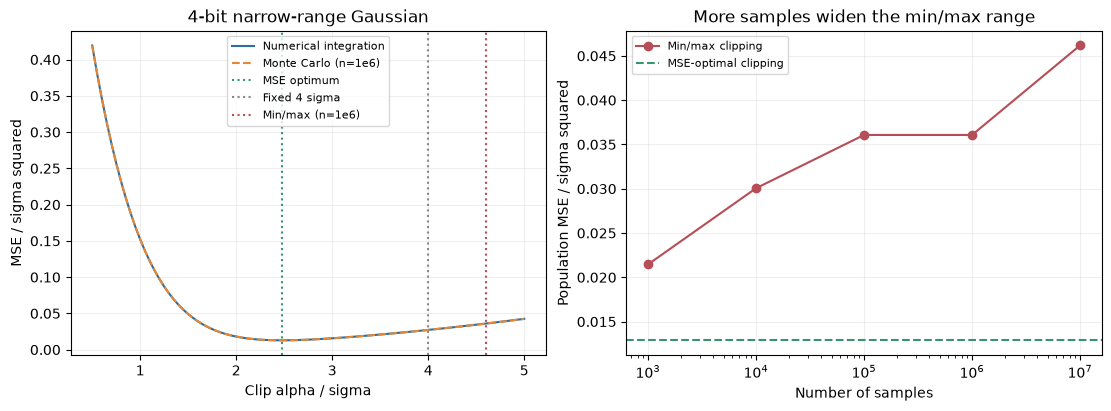

In [3]:
sample_counts = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
minmax_rows = []
print("Samples | min/max alpha | population MSE | sample MSE")
for count in sample_counts:
    current = all_samples[:count]
    alpha = float(current.abs().max())
    population_mse = expected_mse(make_quantizer(alpha), "gaussian")
    sample_mse = float((make_quantizer(alpha)(current) - current).square().mean())
    minmax_rows.append({"samples": count, "alpha": alpha, "mse_integral": population_mse, "mse_mc": sample_mse})
    print(f"{count:8d} | {alpha:.5f} | {population_mse:.7f} | {sample_mse:.7f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(alphas, integral_curve, label="Numerical integration", color="#2E6F9E")
axes[0].plot(alphas, mc_curve, "--", label="Monte Carlo (n=1e6)", color="#E68735")
for label, alpha, color in [("MSE optimum", alpha_star, "#38936F"), ("Fixed 4 sigma", 4, "#888888"), ("Min/max (n=1e6)", alpha_minmax, "#B74D56")]:
    axes[0].axvline(alpha, linestyle=":", color=color, label=label)
axes[0].set(xlabel="Clip alpha / sigma", ylabel="MSE / sigma squared", title="4-bit narrow-range Gaussian")
axes[0].legend(fontsize=8)
axes[1].semilogx(sample_counts, [r["mse_integral"] for r in minmax_rows], "o-", color="#B74D56", label="Min/max clipping")
axes[1].axhline(mse_star, color="#38936F", linestyle="--", label="MSE-optimal clipping")
axes[1].set(xlabel="Number of samples", ylabel="Population MSE / sigma squared", title="More samples widen the min/max range")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(FIGURES / "01_clipping-mse.svg", metadata={"Date": None})
fig.savefig(RESULTS / "01_clipping-mse.png", dpi=140)
plt.show()
report = {"optimal_alpha": alpha_star, "optimal_mse": mse_star, "selected": selected, "minmax": minmax_rows,
          "curve": {"alpha": alphas.tolist(), "integral_mse": integral_curve, "mc_mse": mc_curve}}


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "01_clipping-mse.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m1/01_clipping-mse.json")


Saved results: runs/m1/01_clipping-mse.json


## 직접 확인하기

같은 입력 샘플과 4-bit 설정에서 클립을 2σ와 4σ로 고정해 MSE를 비교해 보자. 두 설정의 클리핑 오차와 양자화 스텝 오차를 나누어 설명할 수 있는가?
